# How `Qdrant/BM25` compute the sparse vector

In [2]:
from collections import Counter
from fastembed.sparse import SparseTextEmbedding


model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS."""

vec = next(model.embed([text]))
print(f"Text: {text} \nLength of text: {len(text)}\n")
print("=== Sparse vector ===")
print("indices:", vec.indices)
print("values:", vec.values)
print("non-zero dimensions:", len(vec.indices))


# Use FastEmbed's real internal BM25 preprocessing
tokens = bm25.tokenizer.tokenize(text.lower())

# Remove stopwords
tokens_no_stopwords = [
    token for token in tokens
    if token not in bm25.stopwords
]

# Stem correctly: pass a list, not one string
if not bm25.disable_stemmer:
    final_terms = bm25._stem(tokens_no_stopwords)
else:
    final_terms = tokens_no_stopwords

# Compute ids from final terms
term_counts = Counter(final_terms)

index_to_value = {
    int(i): float(v)
    for i, v in zip(vec.indices, vec.values)
}

print("\n=== Included terms ===")
print(f"{'term':<40} {'count':<8} {'index':<15} {'value'}")
print("-" * 60)

for term, count in term_counts.items():
    idx = int(bm25.compute_token_id(term))
    value = index_to_value.get(idx, 0.0)

    print(f"{term:<40} {count:<8} {idx:<15} {value}")


print("\n=== Dropped stopwords ===")
dropped = [
    token for token in tokens
    if token in bm25.stopwords
]
print(dropped)

Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS. 
Length of text: 92

=== Sparse vector ===
indices: [1471019746 1298296063  938217065  390168769  801873620 1796268431
 1714506967 1035623941 1270418937]
values: [1.65209739 1.65209739 1.65209739 1.65209739 1.65209739 1.65209739
 1.65209739 1.65209739 1.65209739]
non-zero dimensions: 9

=== Included terms ===
term                                     count    index           value
------------------------------------------------------------
retrospect                               1        1471019746      1.6520973892637139
analysi                                  1        1298296063      1.6520973892637139
conduct                                  1        938217065       1.6520973892637139
332                                      1        390168769       1.6520973892637139
adult                                    1        801873620       1.6520973892637139
patient                         

In [9]:
import math
from collections import Counter
from qdrant_client import QdrantClient, models
from fastembed.sparse import SparseTextEmbedding

model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

# A small toy corpus so we actually have document-frequency stats to work with
corpus = [
    "A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.",
    "Cardiogenic shock patients often require mechanical circulatory support.",
    "AMI-CS carries a high in-hospital mortality rate despite advances in treatment.",
    "This retrospective cohort study analyzed adult patients over five years.",
]

# --- Spin up an in-memory Qdrant instance ---
client = QdrantClient(":memory:")
client.create_collection(
    collection_name="demo",
    sparse_vectors_config={
        "bm25": models.SparseVectorParams(modifier=models.Modifier.IDF)
    },
)

client.upsert(
    collection_name="demo",
    points=[
        models.PointStruct(
            id=i,
            payload={"text": doc},
            vector={"bm25": models.Document(text=doc, model="Qdrant/bm25")},
        )
        for i, doc in enumerate(corpus)
    ],
)

# --- Manually compute IDF the same way Qdrant does, for comparison ---
N = len(corpus)
doc_freq = Counter()  # how many documents each token_id appears in

# embed each document and count how many documents each token_id appears in
for doc in corpus:
    vec = next(model.embed([doc]))
    print(f"Document: {doc}\nIndices: {vec.indices}\n")
    for idx in vec.indices:
        doc_freq[int(idx)] += 1

def qdrant_idf(n_qi, N):
    return math.log((N - n_qi + 0.5) / (n_qi + 0.5) + 1)

print(f"Corpus size N = {N}\n")
print(f"{'term_id':<15}{'doc_freq n(qi)':<18}{'IDF':<10}")
print("-" * 45)
for term_id, n_qi in sorted(doc_freq.items(), key=lambda x: -x[1]):
    print(f"{term_id:<15}{n_qi:<18}{qdrant_idf(n_qi, N):<10.4f}")

# --- Sanity check: run a real query and see the combined BM25 score Qdrant returns ---
query = "retrospective adult patients"
results = client.query_points(
    collection_name="demo",
    query=models.Document(text=query, model="Qdrant/bm25"),
    using="bm25",
    limit=len(corpus),
).points

print("\n=== Qdrant search results (full BM25 score = TF x IDF) ===")
for r in results:
    print(f"score={r.score:.4f}  doc={r.payload['text'][:60]}...")

Document: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.
Indices: [1471019746 1298296063  938217065  390168769  801873620 1796268431
 1714506967 1035623941 1270418937]

Document: Cardiogenic shock patients often require mechanical circulatory support.
Indices: [1064233887 1999205350 1796268431 1285937727  516115046 1207498445
  574692281 1100855371]

Document: AMI-CS carries a high in-hospital mortality rate despite advances in treatment.
Indices: [1035623941 1270418937 1523874731 1612531086  291013412  547113685
 1151308235  663941294  728487644 2114294529]

Document: This retrospective cohort study analyzed adult patients over five years.
Indices: [1471019746 1525777304  150760872  412527760  801873620 1796268431
  297260153  822745112]

Corpus size N = 4

term_id        doc_freq n(qi)    IDF       
---------------------------------------------
1796268431     3                 0.3567    
1471019746     2                 0.6931    
8018736

In [12]:
import math
from collections import Counter
from qdrant_client import QdrantClient, models
from fastembed.sparse import SparseTextEmbedding

model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

corpus = [
    "A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.",
    "Cardiogenic shock patients often require mechanical circulatory support.",
    "AMI-CS carries a high in-hospital mortality rate despite advances in treatment.",
    "This retrospective cohort study analyzed adult patients over five years.",
]

# --- Spin up an in-memory Qdrant instance ---
client = QdrantClient(":memory:")
client.create_collection(
    collection_name="demo",
    sparse_vectors_config={
        "bm25": models.SparseVectorParams(modifier=models.Modifier.IDF)
    },
)
client.upsert(
    collection_name="demo",
    points=[
        models.PointStruct(
            id=i,
            payload={"text": doc},
            vector={"bm25": models.Document(text=doc, model="Qdrant/bm25")},
        )
        for i, doc in enumerate(corpus)
    ],
)

# --- Manually replicate preprocessing per document to track terms, ids, and stopwords ---
N = len(corpus)
doc_freq = Counter()       # term -> number of docs it appears in
term_to_id = {}            # term -> hashed id (for display)
dropped_stopwords_per_doc = []

for doc in corpus:
    tokens = bm25.tokenizer.tokenize(doc.lower())

    dropped = [t for t in tokens if t in bm25.stopwords]
    dropped_stopwords_per_doc.append(dropped)

    kept = [t for t in tokens if t not in bm25.stopwords]
    stemmed = bm25._stem(kept) if not bm25.disable_stemmer else kept

    unique_terms_in_doc = set(stemmed)
    for term in unique_terms_in_doc:
        # calculate document frequency for each term (n(qi))
        doc_freq[term] += 1
        # to map term to its hashed id for display purposes
        term_to_id[term] = int(bm25.compute_token_id(term))

# --- Compute IDF using Qdrant's formula ---
def qdrant_idf(n_qi, N):
    return math.log((N - n_qi + 0.5) / (n_qi + 0.5) + 1)

# --- Print term / id / doc_freq / IDF table ---
print(f"Corpus size N = {N}\n")
print(f"{'term':<18}{'term_id':<15}{'doc_freq n(qi)':<18}{'IDF':<10}")
print("-" * 61)
for term, n_qi in sorted(doc_freq.items(), key=lambda x: -x[1]):
    idf = qdrant_idf(n_qi, N)
    print(f"{term:<18}{term_to_id[term]:<15}{n_qi:<18}{idf:<10.4f}")

# --- Print dropped stopwords per document ---
print("\n=== Dropped stopwords per document ===")
for i, (doc, dropped) in enumerate(zip(corpus, dropped_stopwords_per_doc)):
    print(f"[doc {i}] {doc[:60]}...")
    print(f"Dropped stopwords: {dropped}\n")

# --- Sanity check against real Qdrant search score ---
query = "retrospective adult patients"
results = client.query_points(
    collection_name="demo",
    query=models.Document(text=query, model="Qdrant/bm25"),
    using="bm25",
    limit=len(corpus),
).points

print("=== Qdrant search results (full BM25 score = TF x IDF) ===")
for r in results:
    print(f"score={r.score:.4f}  doc={r.payload['text'][:60]}...")

Corpus size N = 4

term              term_id        doc_freq n(qi)    IDF       
-------------------------------------------------------------
patient           1796268431     3                 0.3567    
adult             801873620      2                 0.6931    
cs                1270418937     2                 0.6931    
retrospect        1471019746     2                 0.6931    
ami               1035623941     2                 0.6931    
diagnos           1714506967     1                 1.2040    
conduct           938217065      1                 1.2040    
332               390168769      1                 1.2040    
analysi           1298296063     1                 1.2040    
requir            516115046      1                 1.2040    
circulatori       574692281      1                 1.2040    
mechan            1207498445     1                 1.2040    
often             1285937727     1                 1.2040    
cardiogen         1064233887     1                 

# Dense Vector

=== Dense vector ===
Model: nomic-embed-text:latest
Vector shape: (768,)
Number of dimensions: 768
Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.
Length of text: 92
First 20 values:
[ 0.12341617  0.47731912 -3.80318975 -0.86197102  0.29201481 -0.09571008
  0.35264501  0.29629505  0.32974315  0.07025451  0.20927286  0.80875099
  1.83334589 -0.70772731 -0.11114966 -1.90498936 -0.26641327 -0.76917195
 -1.31194413  1.27386403]

=== Dense vector stats ===
Min: -3.803189754486084
Max: 1.961925745010376
Mean: 0.005980435071402705
Non-zero values: 768
Zero values: 0


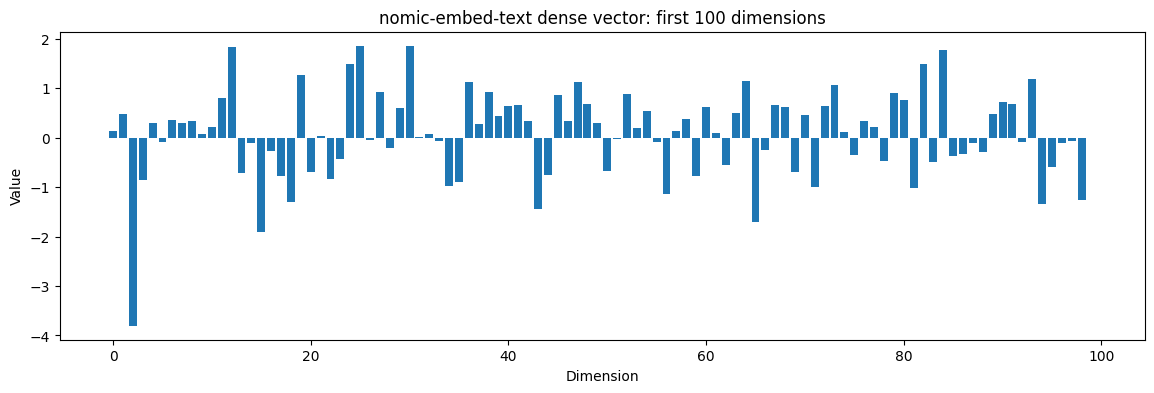

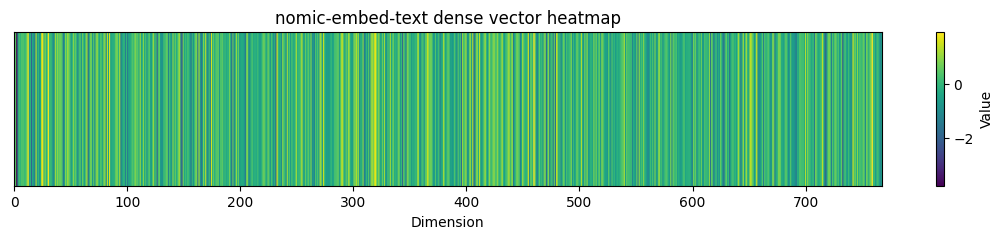

In [2]:
import requests
import numpy as np
import matplotlib.pyplot as plt

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS."""

response = requests.post(
    "http://localhost:11434/api/embeddings",
    json={
        "model": "nomic-embed-text:latest",
        "prompt": text,
    },
)

response.raise_for_status()

vec = np.array(response.json()["embedding"])

print("=== Dense vector ===")
print("Model: nomic-embed-text:latest")
print("Vector shape:", vec.shape)
print("Number of dimensions:", len(vec))
print("Text:", text)
print("Length of text:", len(text))
print("First 20 values:")
print(vec[:20])

print("\n=== Dense vector stats ===")
print("Min:", vec.min())
print("Max:", vec.max())
print("Mean:", vec.mean())
print("Non-zero values:", np.count_nonzero(vec))
print("Zero values:", len(vec) - np.count_nonzero(vec))

# Plot first 100 dimensions
n = 100

plt.figure(figsize=(14, 4))
plt.bar(range(n), vec[:n])
plt.title(f"nomic-embed-text dense vector: first {n} dimensions")
plt.xlabel("Dimension")
plt.ylabel("Value")
plt.show()

# Heatmap-like visualization
plt.figure(figsize=(14, 2))
plt.imshow(vec.reshape(1, -1), aspect="auto")
plt.title("nomic-embed-text dense vector heatmap")
plt.xlabel("Dimension")
plt.yticks([])
plt.colorbar(label="Value")
plt.show()

# Judge-Robust RAG Weakness Analysis

This section compares the same RAG outputs judged by `qwen2.5:7b` and `gpt-5.6-luna`. The goal is not to choose the best response model, but to find query categories where the RAG pipeline is reliably strong or weak across judges.

Use the judge-robust averages as the main signal. Use judge disagreement as a caution flag: when judges disagree strongly, avoid over-interpreting model/category deltas without manual review.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="notebook")
except ImportError:
    sns = None
    plt.style.use("seaborn-v0_8-whitegrid")

JUDGE_COMPARISON_FILES = {
    # ALL PAPER RESULTS 
    # ("Llama", "Qwen 2.5 7B"): Path("results_v3/llama_3_2_3b__qwen2_5_7b.csv"),
    # ("MedLlama", "Qwen 2.5 7B"): Path("results_v3/medllama_2_7b__qwen2_5_7b.csv"),
    # ("Llama", "GPT-5.6 Luna"): Path("results_v4/llama_3_2b__gpt_5_6_luna.csv"),
    # ("MedLlama", "GPT-5.6 Luna"): Path("results_v4/medllama_2_7b__gpt_5_6_luna.csv"),

    # PAPER SPECIFIC RESULTS (v5 and v6)
    ("Llama", "GPT-5.6 Luna"): Path("results_v5/llama_3_2b__gpt_5_6_luna.csv"),
    ("MedLlama", "GPT-5.6 Luna"): Path("results_v5/medllama_2_7b__gpt_5_6_luna.csv"),
    ("Llama", "Qwen 2.5 7B"): Path("results_v6/llama_3_2b__qwen_2_5_7b.csv"),
    ("MedLlama", "Qwen 2.5 7B"): Path("results_v6/medllama_2_7b__qwen_2_5_7b.csv"),
}

frames = []
for (response_model, judge_model), file_path in JUDGE_COMPARISON_FILES.items():
    df = pd.read_csv(file_path)
    df["response_family"] = response_model
    df["judge_family"] = judge_model
    df["run_label"] = f"{response_model} judged by {judge_model}"
    frames.append(df)

judge_results = pd.concat(frames, ignore_index=True)
judge_results["is_correct"] = judge_results["is_correct"].astype(bool)
judge_results.head()

,query_id,eval_unit,paper_index,article_id,article_title,reference_section,reference_status,source_row,api_latency_seconds,retrieved_context_count,...,paper_accuracy,min_paper_correctness,all_papers_correct,query_outcome,response_model,judge_model,embedding_model,response_family,judge_family,run_label
0,1,paper,1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,Methods,reported,2,49.608612,1,...,0.0,0.645346,False,Needs review,llama3.2:3b,gpt-5.6-luna,nomic-embed-text:latest,Llama,GPT-5.6 Luna,Llama judged by GPT-5.6 Luna
1,2,paper,1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,Methods,reported,3,6.875287,1,...,0.0,0.599839,False,Needs review,llama3.2:3b,gpt-5.6-luna,nomic-embed-text:latest,Llama,GPT-5.6 Luna,Llama judged by GPT-5.6 Luna
2,3,paper,1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,Methods,unclear,4,7.291410,1,...,0.0,0.314815,False,Needs review,llama3.2:3b,gpt-5.6-luna,nomic-embed-text:latest,Llama,GPT-5.6 Luna,Llama judged by GPT-5.6 Luna
3,4,paper,1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,Methods,reported,5,3.773629,1,...,0.0,0.333333,False,Needs review,llama3.2:3b,gpt-5.6-luna,nomic-embed-text:latest,Llama,GPT-5.6 Luna,Llama judged by GPT-5.6 Luna
4,5,paper,1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,Methods,reported,6,3.092465,1,...,0.0,0.766224,False,Needs review,llama3.2:3b,gpt-5.6-luna,nomic-embed-text:latest,Llama,GPT-5.6 Luna,Llama judged by GPT-5.6 Luna


## Judge-Robust Category Ranking

This ranks categories by average correctness across both response models and both judges. Categories at the bottom are the most reliable RAG weaknesses because they stay weak even when the judge changes.

Most difficult categories across both judges and both models


,category,mean_correctness,median_correctness,pass_rate,mean_context_recall,mean_context_precision,n
37,window.observation,0.098,0.083,0.0,0.000,0.50,4
11,evaluation.additional_analysis,0.181,0.195,0.0,0.250,0.50,4
1,cohort.clinical_domain,0.210,0.219,0.0,0.000,0.50,4
14,evaluation.explainability,0.210,0.167,0.0,0.250,0.50,4
30,outcome.secondary,0.246,0.239,0.0,0.000,0.00,4
27,outcome.classbalance,0.266,0.263,0.0,0.500,0.25,4
15,evaluation.metrics,0.313,0.320,0.0,0.167,0.50,4
13,evaluation.confidence_interval_and_uncertainty,0.319,0.359,0.0,0.500,1.00,4
16,evaluation.metrics_per_model,0.319,0.362,0.0,0.167,0.50,4
34,processing.repeated_admission,0.331,0.325,0.0,0.250,0.50,4


Best answered categories across both judges and both models


,category,mean_correctness,median_correctness,pass_rate,mean_context_recall,mean_context_precision,n
28,outcome.prediction_task_category,0.923,0.921,0.50,1.00,1.00,4
33,processing.missing,0.813,0.931,0.50,1.00,1.00,4
3,cohort.exclusion,0.812,0.810,0.25,1.00,1.00,4
10,cohort.unit,0.792,0.870,0.25,1.00,1.00,4
32,outcome.target_type,0.779,0.748,0.00,1.00,1.00,4
6,cohort.overview,0.723,0.736,0.00,0.75,1.00,4
17,evaluation.stats_performance_comp,0.712,0.686,0.00,1.00,0.75,4
0,cohort.admission_count,0.683,0.648,0.00,0.50,0.50,4
12,evaluation.best_model,0.651,0.658,0.00,0.50,1.00,4
24,model.methods,0.628,0.622,0.00,0.50,1.00,4


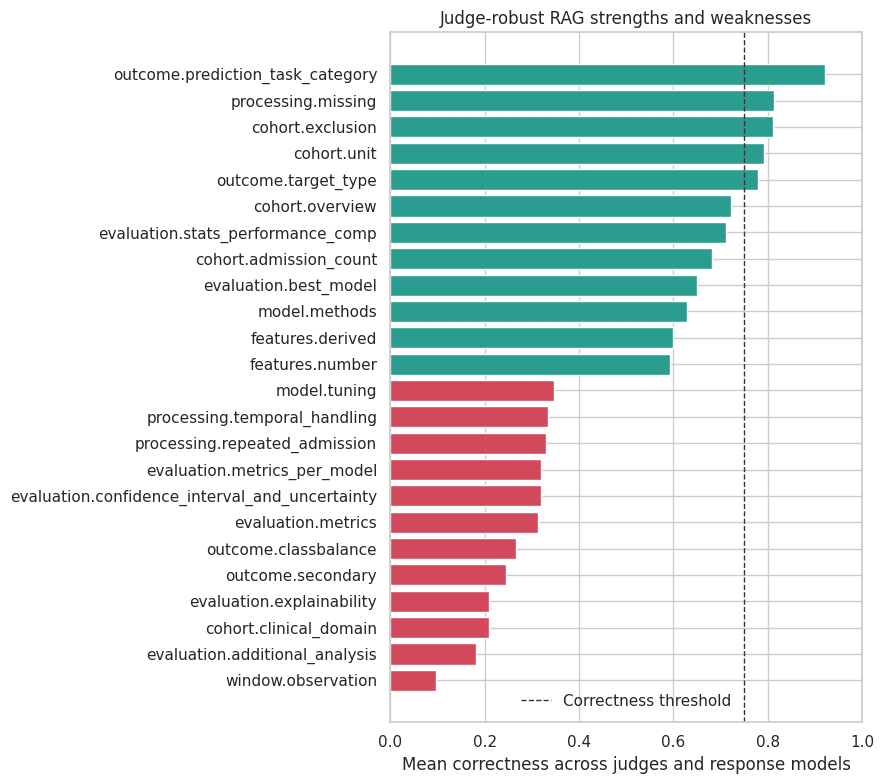

In [3]:
robust_category = (
    judge_results.groupby("category", as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        median_correctness=("correctness_score", "median"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
    .sort_values("mean_correctness")
)

print("Most difficult categories across both judges and both models")
display(robust_category.head(12).round(3))

print("Best answered categories across both judges and both models")
display(robust_category.tail(12).sort_values("mean_correctness", ascending=False).round(3))

plot_df = pd.concat([
    robust_category.head(12).assign(group="Weakest"),
    robust_category.tail(12).assign(group="Strongest"),
])
plot_df = plot_df.sort_values("mean_correctness")

fig, ax = plt.subplots(figsize=(9, 8))
colors = np.where(plot_df["group"].eq("Strongest"), "#2a9d8f", "#d1495b")
ax.barh(plot_df["category"], plot_df["mean_correctness"], color=colors)
ax.axvline(0.75, color="#333", linestyle="--", linewidth=1, label="Correctness threshold")
ax.set_xlabel("Mean correctness across judges and response models")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.set_title("Judge-robust RAG strengths and weaknesses")
ax.legend(frameon=False)
plt.tight_layout()

## Field-Level Weakness

This compresses categories into broader extraction fields. It shows whether the RAG system struggles more with cohort, features, outcomes, processing, modelling, or time-window questions.

,field_id,mean_correctness,pass_rate,mean_context_recall,mean_context_precision,n
6,window,0.230,0.000,0.250,0.750,8
1,evaluation,0.386,0.000,0.405,0.679,28
5,processing,0.477,0.125,0.448,0.750,16
3,modelling,0.507,0.000,0.471,1.000,16
2,features,0.512,0.000,0.525,0.800,20
4,outcome,0.539,0.083,0.708,0.708,24
0,cohort,0.548,0.045,0.621,0.864,44


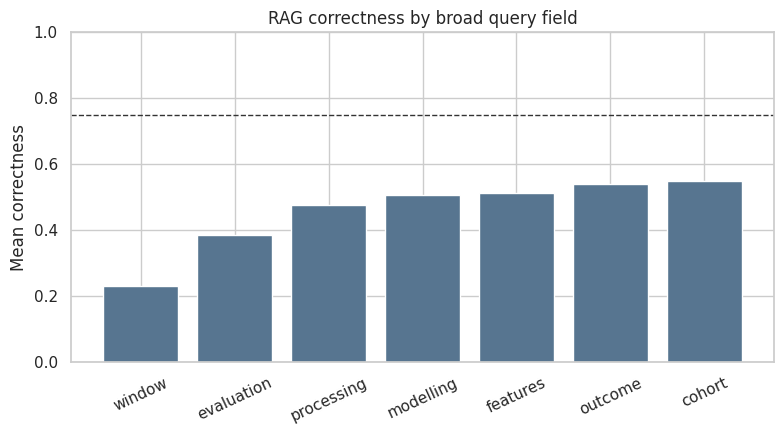

In [4]:
field_summary = (
    judge_results.groupby("field_id", as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
    .sort_values("mean_correctness")
)

display(field_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(field_summary["field_id"], field_summary["mean_correctness"], color="#577590")
ax.axhline(0.75, color="#333", linestyle="--", linewidth=1)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_ylabel("Mean correctness")
ax.set_title("RAG correctness by broad query field")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()

## Judge Disagreement

These categories should be treated carefully. A large judge delta means conclusions depend heavily on whether Qwen or GPT-Luna is judging. Stable hard/easy categories are more useful for diagnosing RAG behavior.

Categories with largest judge disagreement


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
processing.repeated_admission,0.588,0.074,0.514,0.514
cohort.repeated_admissions,0.630,0.159,0.470,0.470
cohort.setting,0.670,0.338,0.333,0.333
features.derived,0.765,0.432,0.333,0.333
feature.temporal_resolution,0.506,0.189,0.317,0.317
processing.selection,0.582,0.278,0.304,0.304
outcome.classbalance,0.405,0.127,0.278,0.278
cohort.admission_count,0.819,0.547,0.272,0.272
evaluation.best_model,0.526,0.776,-0.250,0.250


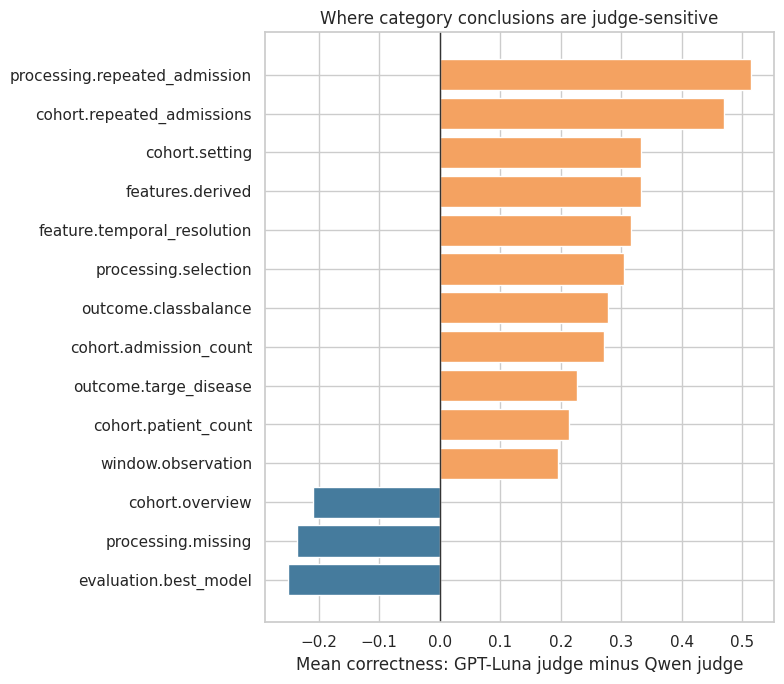

In [5]:
judge_category = (
    judge_results.groupby(["category", "judge_family"], as_index=False)["correctness_score"]
    .mean()
    .pivot(index="category", columns="judge_family", values="correctness_score")
)
# judge_category["GPT-Luna minus Qwen"] = judge_category["GPT-5.6 Luna"] - judge_category["Qwen 2 7B"]
judge_category["GPT-Luna minus Qwen"] = judge_category["GPT-5.6 Luna"] - judge_category["Qwen 2.5 7B"]

judge_category["absolute_judge_delta"] = judge_category["GPT-Luna minus Qwen"].abs()
judge_category = judge_category.sort_values("absolute_judge_delta", ascending=False)

print("Categories with largest judge disagreement")
display(judge_category.head(12).round(3))

fig, ax = plt.subplots(figsize=(8, 7))
top_disagreement = judge_category.head(14).sort_values("GPT-Luna minus Qwen")
colors = np.where(top_disagreement["GPT-Luna minus Qwen"] >= 0, "#f4a261", "#457b9d")
ax.barh(top_disagreement.index, top_disagreement["GPT-Luna minus Qwen"], color=colors)
ax.axvline(0, color="#333", linewidth=1)
ax.set_xlabel("Mean correctness: GPT-Luna judge minus Qwen judge")
ax.set_ylabel("")
ax.set_title("Where category conclusions are judge-sensitive")
plt.tight_layout()

## Stable Strengths And Stable Weaknesses

This filters for categories that both judges agree are weak or strong. These are better candidates for thesis-level claims than model-vs-model deltas.

In [6]:
stable_weak = (
    judge_category[(judge_category["GPT-5.6 Luna"] < 0.40) & (judge_category["Qwen 2.5 7B"] < 0.40)]
    .sort_values(["GPT-5.6 Luna", "Qwen 2.5 7B"])
)
stable_strong = (
    judge_category[(judge_category["GPT-5.6 Luna"] > 0.60) & (judge_category["Qwen 2.5 7B"] > 0.60)]
    .sort_values(["GPT-5.6 Luna", "Qwen 2.5 7B"], ascending=False)
)

print("Stable weaknesses: both judges score below 0.40")
display(stable_weak.round(3))

print("Stable strengths: both judges score above 0.60")
display(stable_strong.round(3))

Stable weaknesses: both judges score below 0.40


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
evaluation.additional_analysis,0.167,0.195,-0.028,0.028
window.observation,0.195,0.000,0.195,0.195
cohort.clinical_domain,0.201,0.219,-0.018,0.018
evaluation.metrics,0.238,0.388,-0.150,0.150
evaluation.explainability,0.254,0.167,0.087,0.087
evaluation.metrics_per_model,0.277,0.362,-0.085,0.085
model.tuning,0.309,0.385,-0.076,0.076
outcome.secondary,0.309,0.183,0.126,0.126
evaluation.confidence_interval_and_uncertainty,0.380,0.259,0.121,0.121


Stable strengths: both judges score above 0.60


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
outcome.prediction_task_category,0.925,0.921,0.004,0.004
cohort.unit,0.870,0.715,0.155,0.155
cohort.exclusion,0.809,0.814,-0.005,0.005
outcome.target_type,0.748,0.809,-0.061,0.061
evaluation.stats_performance_comp,0.747,0.676,0.071,0.071
processing.missing,0.695,0.931,-0.236,0.236
model.methods,0.634,0.622,0.013,0.013
cohort.overview,0.619,0.828,-0.209,0.209


## Retrieval Versus Answering Failure

Low correctness with low context recall suggests retrieval/chunking weakness. Low correctness with high context precision but modest recall often means the system retrieved relevant material but missed specific details during answer extraction.

Lowest-correctness categories with likely failure mode


,category,mean_correctness,mean_context_recall,mean_context_precision,likely_failure_mode,n
37,window.observation,0.098,0.000,0.50,retrieval/chunk recall,4
11,evaluation.additional_analysis,0.181,0.250,0.50,retrieval/chunk recall,4
1,cohort.clinical_domain,0.210,0.000,0.50,retrieval/chunk recall,4
14,evaluation.explainability,0.210,0.250,0.50,retrieval/chunk recall,4
30,outcome.secondary,0.246,0.000,0.00,retrieval/chunk recall,4
27,outcome.classbalance,0.266,0.500,0.25,context ranking/noise,4
15,evaluation.metrics,0.313,0.167,0.50,retrieval/chunk recall,4
13,evaluation.confidence_interval_and_uncertainty,0.319,0.500,1.00,answer extraction/composition,4
16,evaluation.metrics_per_model,0.319,0.167,0.50,retrieval/chunk recall,4
34,processing.repeated_admission,0.331,0.250,0.50,retrieval/chunk recall,4


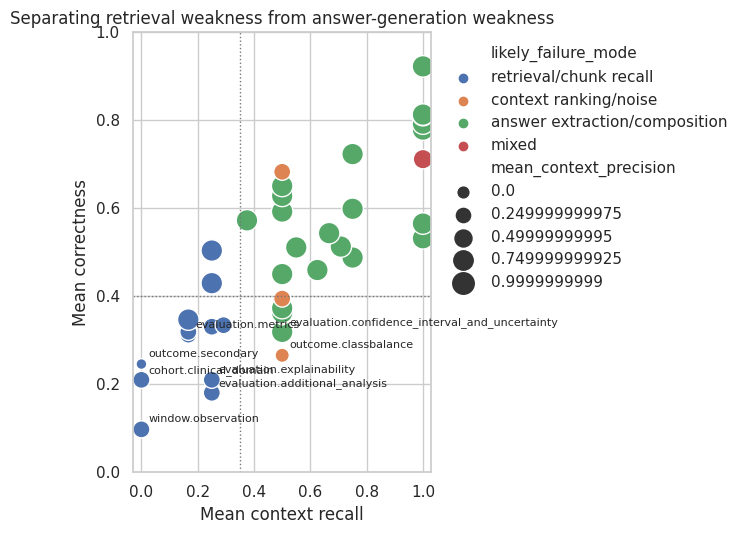

In [7]:
failure_diagnostics = robust_category.copy()
failure_diagnostics["likely_failure_mode"] = np.select(
    [
        failure_diagnostics["mean_context_recall"] < 0.35,
        (failure_diagnostics["mean_context_recall"] >= 0.35) & (failure_diagnostics["mean_context_precision"] >= 0.75),
        failure_diagnostics["mean_context_precision"] < 0.50,
    ],
    [
        "retrieval/chunk recall",
        "answer extraction/composition",
        "context ranking/noise",
    ],
    default="mixed",
)

print("Lowest-correctness categories with likely failure mode")
display(
    failure_diagnostics[
        ["category", "mean_correctness", "mean_context_recall", "mean_context_precision", "likely_failure_mode", "n"]
    ]
    .head(16)
    .round(3)
)

fig, ax = plt.subplots(figsize=(7, 5.5))
if sns:
    sns.scatterplot(
        data=failure_diagnostics,
        x="mean_context_recall",
        y="mean_correctness",
        hue="likely_failure_mode",
        size="mean_context_precision",
        sizes=(60, 240),
        ax=ax,
    )
else:
    ax.scatter(
        failure_diagnostics["mean_context_recall"],
        failure_diagnostics["mean_correctness"],
        s=120,
        alpha=0.75,
    )
for _, row in failure_diagnostics.head(8).iterrows():
    ax.annotate(row["category"], (row["mean_context_recall"], row["mean_correctness"]), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.axhline(0.40, color="#777", linestyle=":", linewidth=1)
ax.axvline(0.35, color="#777", linestyle=":", linewidth=1)
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean context recall")
ax.set_ylabel("Mean correctness")
ax.set_title("Separating retrieval weakness from answer-generation weakness")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## Takeaway

Do not use category-level model deltas as the main diagnostic when judges disagree. For RAG weakness, prioritize categories that are consistently low across judges and response models. In these runs, the most robust weak spots are temporal resolution, temporal features, secondary outcomes, class balance, observation/prediction windows, numeric feature counts, MIMIC-IV table details, and extra/additional analysis questions. The strongest categories are missing-data processing, prediction-task category, reported evaluation metrics, clinical domain, cohort unit/setting, and model-method summaries.


# Where Query Categories Live In The Papers

This section uses the `section` annotations in `datasets/ML4EHR.csv` to identify where each query category is usually answered across the 12 papers. This is a RAG design finding: categories that mostly live in Methods, Results, Abstract/Title, tables, or `Not Reported` should be routed and prompted differently.


In [33]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SECTION_DATASET = Path("datasets/ML4EHR.csv")
section_df = pd.read_csv(SECTION_DATASET, encoding="utf-8-sig")
section_df = section_df.loc[:, [c for c in section_df.columns if not str(c).startswith("Unnamed")]]
section_df = section_df.dropna(how="all")

for col in ["article_id", "article_title", "field_id", "category"]:
    if col in section_df.columns:
        section_df[col] = section_df[col].ffill()

section_df = section_df[section_df["category"].notna() & section_df["section"].notna()].copy()

SECTION_CANONICAL_ORDER = [
    "Title", "Abstract", "Methods", "Results", "Tables", "Discussion", "Supplementary", "Not Reported", "Other"
]

def normalize_section_families(value):
    text = str(value).strip()
    if not text or text.lower() in {"nan", "not reported", "not specified"}:
        return ["Not Reported"]

    normalized = text.lower().replace("methodology", "methods").replace("reults", "results")
    parts = re.split(r"\s*(?:,|/|;|\+|and)\s*", normalized)
    families = []
    for part in parts:
        part = part.strip(" .")
        if not part:
            continue
        if "not reported" in part:
            families.append("Not Reported")
        elif "table" in part:
            families.append("Tables")
        elif "title" in part:
            families.append("Title")
        elif "abstract" in part:
            families.append("Abstract")
        elif "method" in part:
            families.append("Methods")
        elif "result" in part:
            families.append("Results")
        elif "discussion" in part:
            families.append("Discussion")
        elif "supplement" in part:
            families.append("Supplementary")
        else:
            families.append("Other")
    return list(dict.fromkeys(families)) or ["Other"]

section_rows = []
for _, row in section_df.iterrows():
    families = normalize_section_families(row["section"])
    for family in families:
        section_rows.append({
            "article_id": row.get("article_id"),
            "article_title": row.get("article_title"),
            "field_id": row.get("field_id"),
            "category": row.get("category"),
            "original_section": row.get("section"),
            "section_family": family,
        })

category_sections_long = pd.DataFrame(section_rows)
category_sections_long.head()

,article_id,article_title,field_id,category,original_section,section_family
0,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.overview,Methods,Methods
1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.setting,Methods,Methods
2,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.mimiciv_tables,Methods,Methods
3,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.inclusion,Methods,Methods
4,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.exclusion,Methods,Methods


## Category By Section Table

This table shows, for every query category, how many annotated answers fall in each paper section family across the 12 papers. Use `total_mentions` to spot categories that are spread across multiple sections, and `dominant_share` to see how concentrated a category is.

In [34]:
section_counts = (
    category_sections_long.groupby(["field_id", "category", "section_family"], as_index=False)
    .agg(section_mentions=("section_family", "size"))
)
section_counts["total_mentions"] = section_counts.groupby("category")["section_mentions"].transform("sum")
section_counts["share"] = section_counts["section_mentions"] / section_counts["total_mentions"]

section_count_table = section_counts.pivot_table(
    index=["field_id", "category"],
    columns="section_family",
    values="section_mentions",
    fill_value=0,
    aggfunc="sum",
)
ordered_section_cols = [col for col in SECTION_CANONICAL_ORDER if col in section_count_table.columns]
section_count_table = section_count_table[ordered_section_cols]
section_count_table["total_mentions"] = section_count_table.sum(axis=1)
section_count_table["dominant_section"] = section_count_table[ordered_section_cols].idxmax(axis=1)
section_count_table["dominant_share"] = (
    section_count_table[ordered_section_cols].max(axis=1) / section_count_table["total_mentions"]
)

section_count_table = section_count_table.sort_index()
display(section_count_table.style.format({"dominant_share": "{:.1%}"}))

## Category By Section Percentages

Same table, but normalized within each category. This makes mixed-section categories easier to see.

In [35]:
section_share_table = section_count_table[ordered_section_cols].div(
    section_count_table["total_mentions"], axis=0
)
section_share_table = section_share_table.join(
    section_count_table[["dominant_section", "dominant_share"]]
)

display(section_share_table.style.format({col: "{:.1%}" for col in ordered_section_cols + ["dominant_share"]}))

## Section Distribution Plots

The first plot shows the dominant section histogram: how many query categories mostly belong to each paper section. The second plot shows the full section mix for every category.

,section_family,category_count
0,Title,1
1,Abstract,1
2,Methods,27
3,Results,8
6,Not Reported,2


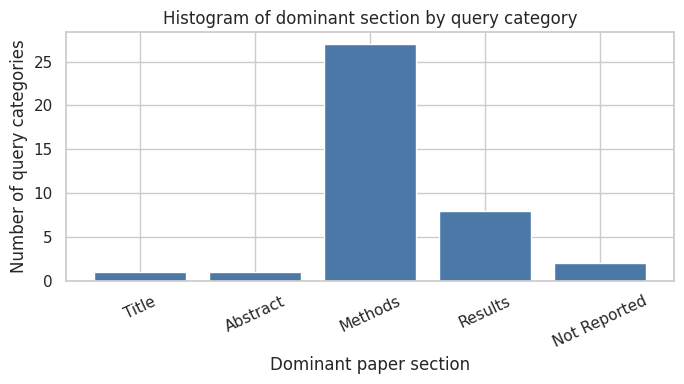

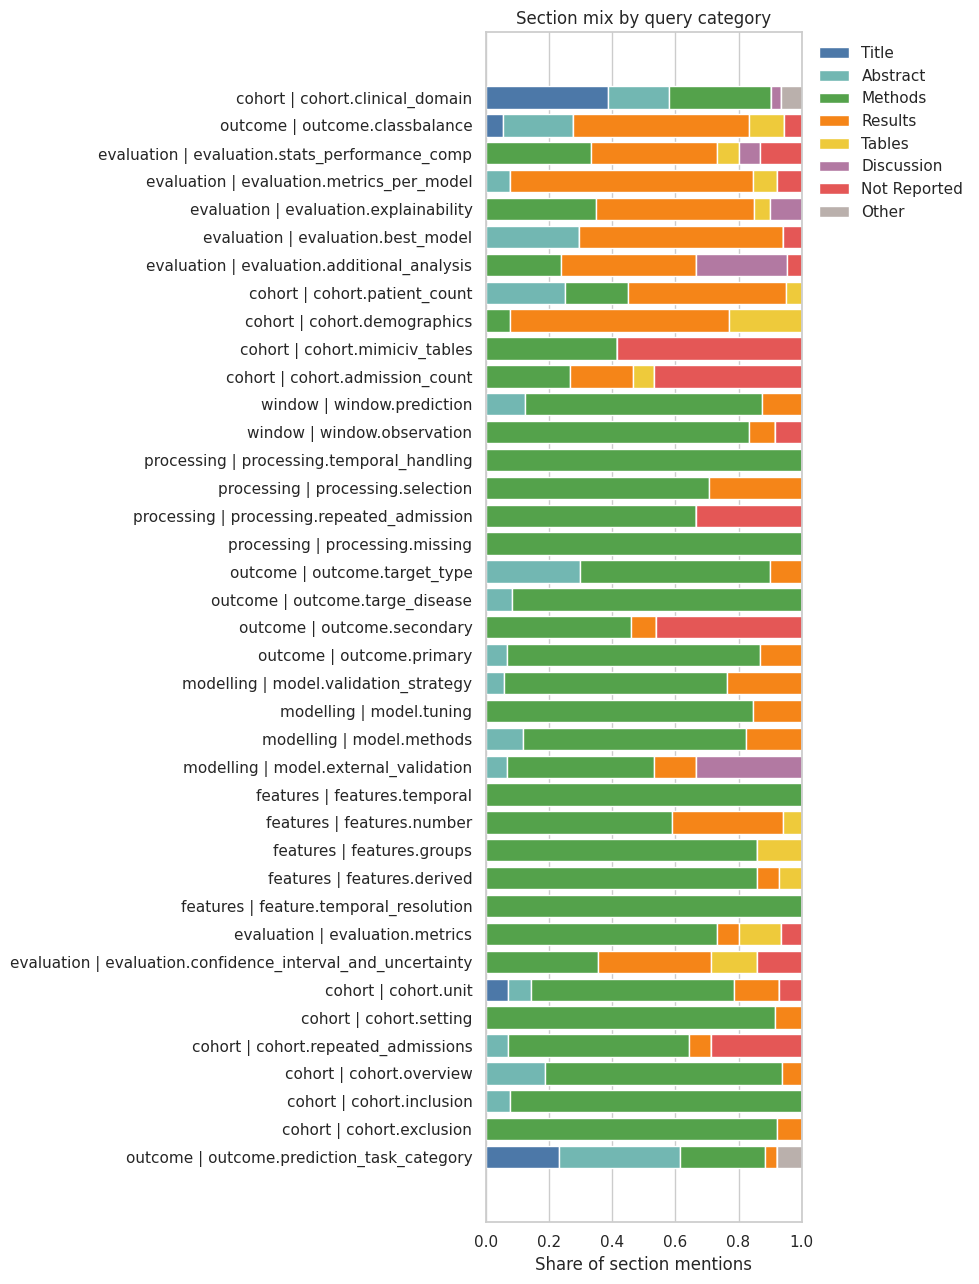

In [36]:
dominant_counts = (
    section_count_table["dominant_section"]
    .value_counts()
    .reindex(ordered_section_cols, fill_value=0)
    .reset_index()
)
dominant_counts.columns = ["section_family", "category_count"]

display(dominant_counts[dominant_counts["category_count"] > 0])

fig, ax = plt.subplots(figsize=(7, 4))
plot_counts = dominant_counts[dominant_counts["category_count"] > 0]
ax.bar(plot_counts["section_family"], plot_counts["category_count"], color="#4c78a8")
ax.set_xlabel("Dominant paper section")
ax.set_ylabel("Number of query categories")
ax.set_title("Histogram of dominant section by query category")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()

category_order = (
    section_count_table
    .sort_values(["dominant_section", "field_id", "category"])
    .index
)
stacked = section_share_table.loc[category_order, ordered_section_cols]

fig, ax = plt.subplots(figsize=(10, 13))
left = np.zeros(len(stacked))
colors = {
    "Title": "#4c78a8",
    "Abstract": "#72b7b2",
    "Methods": "#54a24b",
    "Results": "#f58518",
    "Tables": "#eeca3b",
    "Discussion": "#b279a2",
    "Supplementary": "#9d755d",
    "Not Reported": "#e45756",
    "Other": "#bab0ac",
}
for col in ordered_section_cols:
    values = stacked[col].to_numpy()
    ax.barh(
        [f"{field} | {category}" for field, category in stacked.index],
        values,
        left=left,
        label=col,
        color=colors.get(col, None),
    )
    left += values
ax.set_xlim(0, 1)
ax.set_xlabel("Share of section mentions")
ax.set_ylabel("")
ax.set_title("Section mix by query category")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## Compact Routing Table

This is a concise version for reporting: each category, its dominant section, and a practical retrieval hint.

In [37]:
category_section_map = section_count_table.reset_index()[
    ["field_id", "category", "dominant_section", "dominant_share", "total_mentions"]
].copy()
category_section_map["routing_hint"] = np.select(
    [
        category_section_map["dominant_section"].eq("Methods"),
        category_section_map["dominant_section"].eq("Results"),
        category_section_map["dominant_section"].isin(["Title", "Abstract"]),
        category_section_map["dominant_section"].eq("Tables"),
        category_section_map["dominant_section"].eq("Not Reported"),
    ],
    [
        "Retrieve Methods first",
        "Retrieve Results and table-adjacent chunks first",
        "Retrieve Title/Abstract first, then Methods",
        "Retrieve serialized tables and captions first",
        "Prompt for explicit not-reported handling",
    ],
    default="Use broad section retrieval",
)

display(
    category_section_map
    .sort_values(["field_id", "category"])
    .style.format({"dominant_share": "{:.1%}"})
)

section_family,field_id,category,dominant_section,dominant_share,total_mentions,routing_hint
0,cohort,cohort.admission_count,Not Reported,46.7%,15,Prompt for explicit not-reported handling
1,cohort,cohort.clinical_domain,Title,38.7%,31,"Retrieve Title/Abstract first, then Methods"
2,cohort,cohort.demographics,Results,69.2%,13,Retrieve Results and table-adjacent chunks first
3,cohort,cohort.exclusion,Methods,92.3%,13,Retrieve Methods first
4,cohort,cohort.inclusion,Methods,92.3%,13,Retrieve Methods first
5,cohort,cohort.mimiciv_tables,Not Reported,58.3%,12,Prompt for explicit not-reported handling
6,cohort,cohort.overview,Methods,75.0%,16,Retrieve Methods first
7,cohort,cohort.patient_count,Results,50.0%,20,Retrieve Results and table-adjacent chunks first
8,cohort,cohort.repeated_admissions,Methods,57.1%,14,Retrieve Methods first
9,cohort,cohort.setting,Methods,91.7%,12,Retrieve Methods first


## Finding

Across the 12 papers, the query categories are mostly Methods-oriented, with a smaller Results/table-oriented group and a few Title/Abstract or Not Reported categories. This supports a category-aware RAG strategy: route Methods-heavy questions to study-design, cohort, outcome-definition, feature-engineering, modelling, and preprocessing chunks; route Results-heavy questions to results and table-adjacent chunks; and handle Not Reported categories with explicit absence detection instead of forcing an inferred answer.